# Regime structure in an optoelectronic feedback oscillator

**Author:** Kevin L. Joiner, Ph.D. — [github.com/kvnjnr31](https://github.com/kvnjnr31)

This notebook analyzes audio recordings of a light-driven nonlinear feedback circuit — the
optoelectronic "nightlight" oscillator from
[Joiner, Palmero & Carretero-González, *Int. J. Bifurcation and Chaos* 26(05), 2016](https://doi.org/10.1142/S0218127416500802).
A directional microphone captured the circuit's brightness-modulated acoustic signal; the envelope of
that signal tracks the oscillator's state over time.

The circuit was recorded in several runs that show visibly different dynamics. Here they are labeled
`Regime 1-4` in order of increasing waveform complexity (a provisional, not formally verified, ordering).
This notebook addresses the
question:

> **Do unsupervised features of the audio envelope separate the recordings into distinct groups, and do they have
> visibly different phase-space geometry?**

The workflow is **pandas** (build a feature table from the raw audio), **scipy** (envelope + spectral
features), and **scikit-learn** (standardize → PCA → KMeans, scored by silhouette). The claims are kept
to what the data supports: the recordings separate by their envelope dynamics, and their reconstructed
attractors differ — no classifier is trained, because with only a handful of independent recordings an
honest supervised accuracy cannot be validated.

In [1]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks
from scipy.io import wavfile

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

DATA = pathlib.Path("data")
pd.set_option("display.width", 100)

# Each recording, labeled Regime 1-4 in order of increasing waveform complexity (provisional ordering).
# TODO: Get the filenames standardized with intuitive names.
RECORDINGS = [
    ("regime_01.wav", "Regime 1"),  #clearly-periodic
    ("regime_02.wav", "Regime 2"),  #different-periodic
    ("regime_03.wav", "Regime 3"),  #different-periodic
    ("regime_04.wav", "Regime 4"),  #possibly chaotic
    
]

## 1. The raw signal and its envelope

The audio itself is a fast carrier; the *information* is in its amplitude envelope — the slow rise and
fall of brightness. A standard envelope detector (full-wave rectify, then low-pass filter) recovers it.

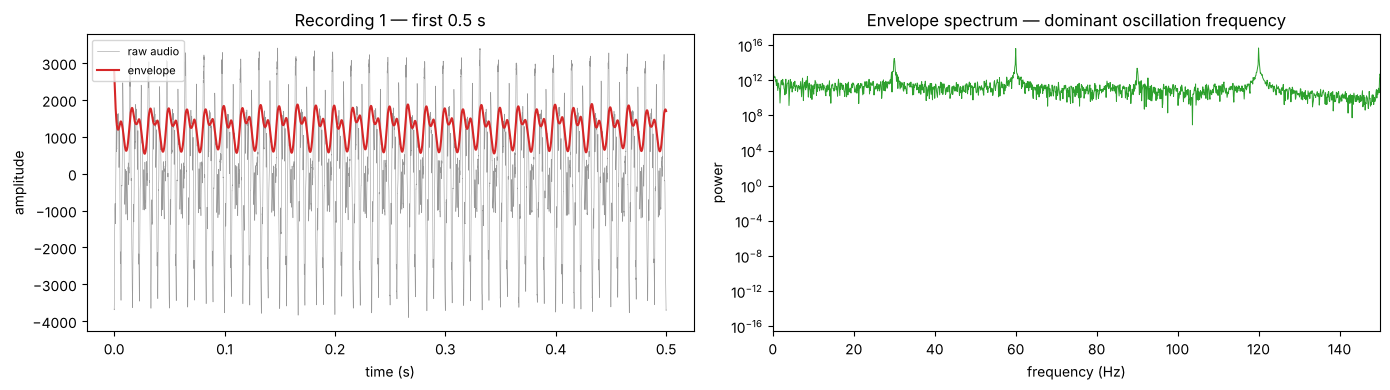

In [2]:
def load_audio(path):
    sr, data = wavfile.read(path)
    if data.ndim == 2:            # stereo -> mono
        data = data.mean(axis=1)
    return sr, data.astype(float)

def envelope(x, sr, cutoff_hz=120):
    """Full-wave rectify then zero-phase low-pass — the amplitude envelope of the signal."""
    b, a = butter(2, cutoff_hz / (0.5 * sr), btype="low")
    return filtfilt(b, a, np.abs(x))

sr, demo = load_audio(DATA / "regime_01.wav")
demo = demo - demo.mean()
env_demo = envelope(demo, sr)
t = np.arange(len(demo)) / sr

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
n = int(0.5 * sr)
axes[0].plot(t[:n], demo[:n], lw=0.4, color="0.6", label="raw audio")
axes[0].plot(t[:n], env_demo[:n], lw=1.5, color="tab:red", label="envelope")
axes[0].set(xlabel="time (s)", ylabel="amplitude", title="Recording 1 — first 0.5 s")
axes[0].legend(fontsize=8)

e = env_demo - env_demo.mean()
fr = np.fft.rfftfreq(len(e), 1 / sr); P = np.abs(np.fft.rfft(e)) ** 2
axes[1].semilogy(fr, P, lw=0.7, color="tab:green")
axes[1].set(xlim=(0, 150), xlabel="frequency (Hz)", ylabel="power",
            title="Envelope spectrum — dominant oscillation frequency")
fig.tight_layout()

## 2. A feature table over sliding windows

Each recording is cut into 0.3 s windows (50% overlap). For every window, a small set of
envelope descriptors with `scipy`, are extracted. These are then collected into a tidy **pandas** DataFrame — one row per
window. These are the features the unsupervised step will see.

In [3]:
def window_features(x, sr):
    x = x - x.mean()
    e = envelope(x, sr); e = e - e.mean()
    fr = np.fft.rfftfreq(len(e), 1 / sr); P = np.abs(np.fft.rfft(e)) ** 2
    band = (fr >= 5) & (fr <= 200)
    dom = fr[band][np.argmax(P[band])]
    centroid = (fr[band] * P[band]).sum() / P[band].sum()
    bandwidth = np.sqrt(((fr[band] - centroid) ** 2 * P[band]).sum() / P[band].sum())
    ac = np.correlate(e, e, "full")[len(e) - 1:]; ac /= ac[0]
    peaks, _ = find_peaks(ac, height=0.2)
    period = peaks[0] / sr if len(peaks) else np.nan
    zerocross = ((e[:-1] * e[1:]) < 0).sum() / (len(e) / sr)
    return {
        "dom_freq_Hz": dom, "spec_centroid_Hz": centroid, "spec_bandwidth_Hz": bandwidth,
        "env_period_s": period, "env_zerocross_Hz": zerocross,
        "rms": np.sqrt((x ** 2).mean()), "env_rms": np.sqrt((e ** 2).mean()), "ptp": np.ptp(x),
    }

rows = []
for fname, regime in RECORDINGS:
    sr, s = load_audio(DATA / fname)
    W, hop = int(0.3 * sr), int(0.15 * sr)
    for i in range(0, len(s) - W, hop):
        r = window_features(s[i:i + W], sr)
        r["recording"] = fname.replace(".wav", "")
        r["regime"] = regime
        rows.append(r)

df = pd.DataFrame(rows).dropna().reset_index(drop=True)
FEATURES = ["dom_freq_Hz", "spec_centroid_Hz", "spec_bandwidth_Hz", "env_period_s",
            "env_zerocross_Hz", "rms", "env_rms", "ptp"]
print(f"{len(df)} windows from {df.recording.nunique()} recordings")
df.groupby("regime")[["dom_freq_Hz", "spec_centroid_Hz", "env_period_s"]].agg(["mean", "std"]).round(2)

316 windows from 4 recordings


dom_freq_Hz        spec_centroid_Hz       env_period_s      
                mean    std             mean   std         mean   std
regime                                                               
Regime 1      111.72  20.87            89.46  4.52         0.02  0.00
Regime 2       20.00   0.00            47.49  4.43         0.05  0.00
Regime 3       19.89   0.59            30.59  1.29         0.05  0.00
Regime 4       19.88   1.32            32.45  3.24         0.06  0.02

The group means already separate by their envelope dynamics (dominant frequency, period, spectral
centroid), which is the signal the unsupervised step below picks up on. The next step asks
whether an *unsupervised* method finds this structure without being told the labels.

## 3. Unsupervised structure — PCA and KMeans

Features are standardized, projected to two principal components, and clustered with KMeans (k = 2).
The clustering never sees the regime labels; I only use them afterward to interpret the clusters.

In [4]:
X = StandardScaler().fit_transform(df[FEATURES])
pca = PCA(n_components=2).fit(X)
Z = pca.transform(X)
print(f"PCA explained variance: {pca.explained_variance_ratio_[:2].round(3)} "
      f"(cumulative {pca.explained_variance_ratio_[:2].sum():.3f})")

# Let the data choose the number of clusters: sweep k and read the silhouette score.
print("\nSilhouette by number of clusters:")
for k in range(2, 6):
    labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
    print(f"  k={k}: silhouette = {silhouette_score(X, labels):.3f}")

# Fit at the chosen k (set from the sweep above).
K_CLUSTERS = 3
km = KMeans(n_clusters=K_CLUSTERS, n_init=10, random_state=0).fit(X)
df["cluster"] = km.labels_
print(f"\nChosen k = {K_CLUSTERS}, silhouette = {silhouette_score(X, km.labels_):.3f}")
print("\nMean dominant frequency per cluster (Hz):")
print(df.groupby("cluster")["dom_freq_Hz"].mean().round(1).to_string())
print("\nCluster vs. recording:")
print(pd.crosstab(df.cluster, df.regime))

PCA explained variance: [0.585 0.301] (cumulative 0.886)

Silhouette by number of clusters:
  k=2: silhouette = 0.619
  k=3: silhouette = 0.623
  k=4: silhouette = 0.638
  k=5: silhouette = 0.562



Chosen k = 3, silhouette = 0.623

Mean dominant frequency per cluster (Hz):
cluster
0     19.9
1     20.0
2    111.7

Cluster vs. recording:
regime   Regime 1  Regime 2  Regime 3  Regime 4
cluster                                        
0               0         0        63        73
1               0       112         0        10
2              58         0         0         0


The silhouette sweep selects the number of clusters from the data rather than assuming it. The windows
separate into distinct groups whose mean envelope frequencies differ, and the cross-tabulation shows how
the recordings map onto those clusters.

**Honest caveat:** the recordings were labeled `Regime 1-4` in order of increasing waveform complexity,
not by a formally verified period / chaos classification. With only four independent recordings, these
clusters are *suggestive* of distinct dynamical states, not proof of a specific bifurcation structure —
confirming that would need delay-embedding invariants (correlation dimension, a Lyapunov exponent) and
more recordings. The clustering is reported as the structure the features actually support.

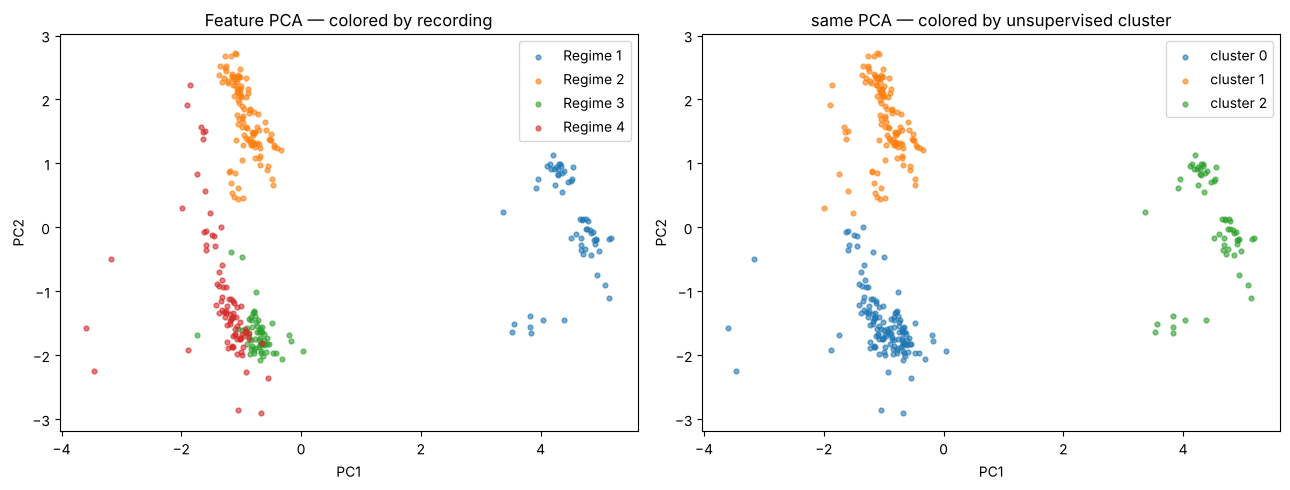

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for reg in sorted(df.regime.unique()):
    m = df.regime == reg
    axes[0].scatter(Z[m, 0], Z[m, 1], s=12, alpha=0.6, label=reg)
axes[0].set(xlabel="PC1", ylabel="PC2", title="Feature PCA — colored by recording")
axes[0].legend()
for cl in sorted(df.cluster.unique()):
    m = df.cluster == cl
    axes[1].scatter(Z[m, 0], Z[m, 1], s=12, alpha=0.6, label=f"cluster {cl}")
axes[1].set(xlabel="PC1", ylabel="PC2", title="same PCA — colored by unsupervised cluster")
axes[1].legend()
fig.tight_layout()

## 4. Phase-space reconstruction — the attractors

Beyond statistics, the recordings have different *geometry*. Takens' delay embedding reconstructs each
oscillator trajectory in phase space by plotting the envelope against a delayed copy of itself,
E(t) vs E(t + τ). A clean closed orbit is the signature of deterministic (not random) dynamics; added
loops or a space-filling tangle indicate period-doubling or chaos.

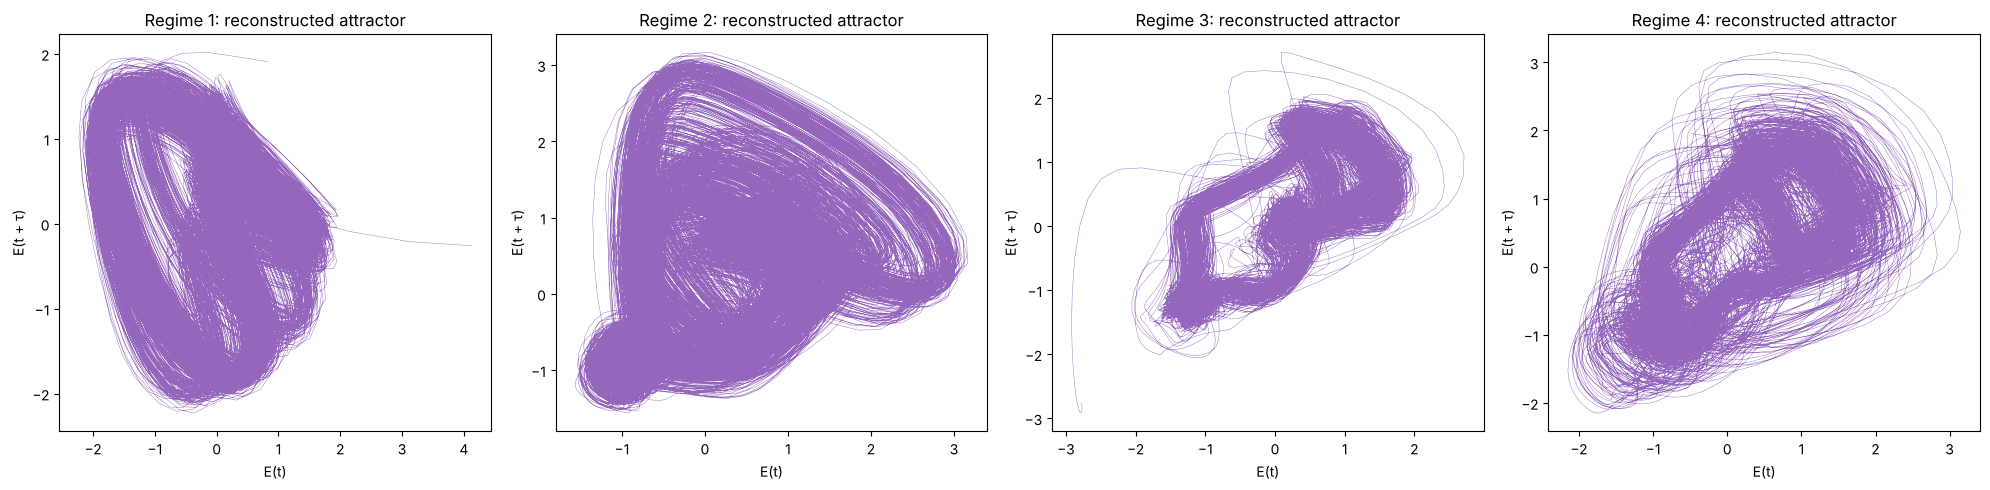

In [6]:
def delay_embed(path, tau=8, decim=20):
    sr, s = load_audio(path)
    e = envelope(s, sr)[::decim]
    e = (e - e.mean()) / e.std()
    return e[:-tau], e[tau:]

# Show all four recordings' attractors, ordered by increasing waveform complexity (Regime 1 -> 4).
fig, axes = plt.subplots(1, len(RECORDINGS), figsize=(5 * len(RECORDINGS), 5))
for ax, (fname, regime) in zip(np.atleast_1d(axes), RECORDINGS):
    x, y = delay_embed(DATA / fname)
    ax.plot(x, y, lw=0.3, color="tab:purple")
    ax.set(xlabel="E(t)", ylabel="E(t + τ)", title=f"{regime}: reconstructed attractor")
fig.tight_layout()

The attractors differ visibly across the recordings: simpler closed orbits for the lower-complexity
recordings, more folded / structured orbits for the higher-complexity ones — consistent with the
strangeness ordering used to label them, though a formal classification would need the invariants noted
above. The envelope carries enough deterministic structure to reconstruct a recognizable attractor from
a microphone recording of a $10 circuit.

## 5. Summary

- Built a windowed feature table from raw audio with **pandas** + **scipy** (envelope, spectral, and
  autocorrelation descriptors).
- **Unsupervised** standardize → PCA → KMeans, with the cluster count chosen by silhouette score rather
  than assumed, separates the recordings into distinct groups — without being given labels.
- **Delay-embedding** shows the recordings have visibly different phase-space geometry.

**What I deliberately did not do:** train a supervised regime classifier. With only a few independent
recordings, a model can score well in-sample while learning recording-specific quirks; an honest
out-of-recording validation isn't possible at this sample size, so a reported accuracy would be
misleading. The unsupervised result above is the claim the data actually supports.

Data and the circuit are from the author's published optoelectronic-chaos work; this notebook is a
compact, reproducible analysis of the recorded dynamics.